# All plots of in vivo data are done here

In [1]:
%load_ext autoreload
%autoreload 2

%matplotlib widget

from hypermri import BrukerDir
from hypermri.sequences import umpireMGE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.style
import matplotlib as mpl
from hypermri.utils.utils_interpolation import interpolate_3d_array
import matplotlib.gridspec as gridspec
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.cm as cm
import cv2
from matplotlib.colors import LinearSegmentedColormap

from joblib import Parallel, delayed

## Multi MEpHISDO slices plotted

In [2]:
font = {'family' : 'Arial',
        'weight' : 'bold',
        #'linespacing' : '1.5',
        'size'   : 11}
legend_properties  = {'family' : 'Arial',
        'weight' : 'bold',
        'stretch' : 'condensed',
          #'linespacing' : '1.5',
        'size'   : 11}

mpl.rc('font', **font)

figsize = [7.08661/1.9,3.5/1.9]

SCALEBAR_ARGS = dict(
    dx=1,
    units="mm",
    location="lower right",
    color="white",
    height_fraction=0.03,
    length_fraction=0.2,
    scale_loc="top",
    sep = 1,
    font_properties = font,
    scale_formatter = lambda value, unit: f"{value}{unit}"
)

MV = lambda x: np.moveaxis(x, 0, 2)

In [3]:
def apply_shift(anat_image, mat_hyper, mat_anat, fov_hyper, fov_anat):
    # function is used to compensate shift of high resolution anatomical images and low resolution CSI and MEpHISDO data caused by unequal defintition of voxel center

    # calculate the resultions ():
    res_bssfp = [a / b for a, b in zip(fov_hyper, mat_hyper)]
    res_anat = [a / b for a, b in zip(fov_anat, mat_anat)]
    shift_vox_list = [d * (a - b) / 2 / c for a, b, c, d in zip(res_bssfp, res_anat, fov_anat, mat_anat)]

    shift_vox = [0, 0, 0]
    # front/back:
    shift_vox[0] = shift_vox_list[0]
    # left/right, x-dim of array echoes-z-x-y-rep-chans
    shift_vox[1] = shift_vox_list[1]
    # y-dim of array echoes-z-x-y-rep-chans
    # shift_vox = [0, 0]
    shift_vox[2] = -shift_vox_list[2]

    from scipy.ndimage import shift

    # shift image:
    return shift(anat_image, shift_vox, mode="wrap")

def get_mask_contours(mask):
    gx, gy = np.gradient(mask)

    temp_edge = gy * gy + gx * gx

    temp_edge[temp_edge != 0.0] = 255.0
    temp_edge = np.asarray(temp_edge, dtype=np.uint8)
    
    return temp_edge

In [4]:
# set colormap for plotting of mask contours
ncolors = 256
color_array = plt.get_cmap('binary_r')(range(ncolors))

# change of zero
color_array[0:3,-1] = 0.0

# create a colormap object
map_object = LinearSegmentedColormap.from_list(name='maks_contour_cmap',colors=color_array)

# register this new colormap with matplotlib
plt.colormaps.register(cmap=map_object)

In [ ]:
scan_nr = 1

In [ ]:
df = pd.read_excel("./OVERVIEW_SequenceComparison_September2025_noresults.xlsx")
# make scan nr the index
df.set_index('Scan_Nr', inplace=True)
META = df.loc[scan_nr]
raw_data_path = META['Raw_Data_Path']

scans = BrukerDir(raw_data_path,verbose =False)

anatomical = scans[META['ExpNr_Anatomical_uMGE']]
uMGE= umpireMGE.load(f"export/MEpHISDO_object_scan_{scan_nr}.pickle")
uMGE.mask_cost_error(cost_error_thr=1.6)


extent_anat = 0, anatomical.fov[1], 0, anatomical.fov[0]
extent_hyper = 0, uMGE.pvm_fov[1], 0, uMGE.pvm_fov[0]
extent_anat, extent_hyper

  0%|          | 0/31 [00:00<?, ?it/s]

C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\base_anatomy.py:82: UserWarning: Could not reorient seq2d.
  warning.warn("Could not reorient seq2d.")
C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\base_anatomy.py:82: UserWarning: Could not reorient seq2d.
  warning.warn("Could not reorient seq2d.")
C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\base_anatomy.py:82: UserWarning: Could not reorient seq2d.
  warning.warn("Could not reorient seq2d.")
[CRITICAL] hypermri.sequences.CSI: [ExpNum=27] The following error occured during shift_kspace():
    Exception: Shift not yet implemented for  read orientation: H_Ffor slice_orient: coronal
 
[CRITICAL] hypermri.sequences.CSI: [ExpNum=28] The following error occured during shift_kspace():
    Exception: Shift not yet implemented for  read orientation: H_Ffor slice_orient: coronal
 
C:\Users\Admin\OneDrive - TUM

((0, 54, 0, 60), (0, 54, 0, 60))

C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\umpireMGE\umpireMGE.py:160: RuntimeWarning: invalid value encountered in divide
  out = np.abs(self._fmap_err / self._fmap) * 100
C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\umpireMGE\_plot_modes.py:32: RuntimeWarning: All-NaN axis encountered
  return self.min_func(self.data)
C:\Users\Admin\anaconda3\envs\hypermri_env_oneDrive\lib\site-packages\jupyter_client\session.py:719: UserWarning: Message serialization failed with:
Out of range float values are not JSON compliant
Supporting this message is deprecated in jupyter-client 7, please make sure your message is JSON-compliant
  content = self.pack(content)


Output()

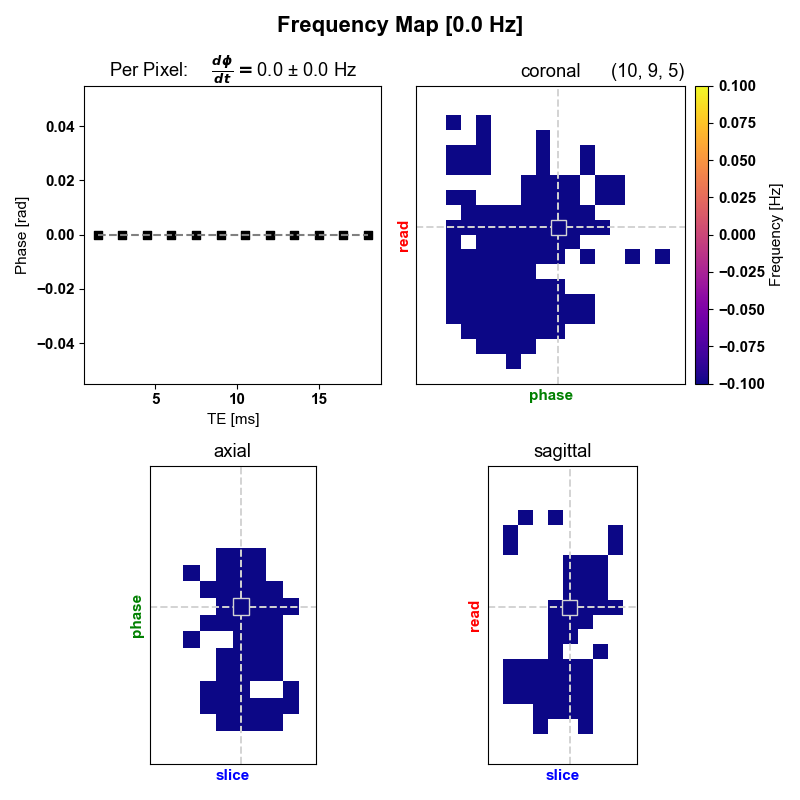

In [7]:
uMGE.plot_results(anatref=anatomical)

In [ ]:
#load fitted pH and frequency maps
pHmap_Comp1 = np.load(f"./export/CSI_pHmap_Comp1_updated_noise_Scan{scan_nr}.npy")
fmap_Comp1 = np.load(f"./export/CSI_fmap_C5_1_updated_noise_Scan{scan_nr}.npy")
ampl_Comp1 = np.load(f"./export/CSI_amplitudes_Comp1_updated_noise_Scan{scan_nr}.npy")

pHmap_Comp2 = np.load(f"./export/CSI_pHmap_Comp2_updated_noise_Scan{scan_nr}.npy")
fmap_Comp2 = np.load(f"./export/CSI_fmap_C5_2_updated_noise_Scan{scan_nr}.npy")
ampl_Comp2 = np.load(f"./export/CSI_amplitudes_Comp2_updated_noise_Scan{scan_nr}.npy")

pHmap_Comp3 =  np.load(f"./export/CSI_pHmap_Comp3_updated_noise_Scan{scan_nr}.npy")
fmap_Comp3 = np.load(f"./export/CSI_fmap_C5_3_updated_noise_Scan{scan_nr}.npy")
ampl_Comp3 = np.load(f"./export/CSI_amplitudes_Comp3_updated_noise_Scan{scan_nr}.npy")



umge_dummy_class = umpireMGE(scans[META['ExpNr_uMGE_Hyper']], self_reco=True)

# dummy shape
shape = np.asarray(uMGE._multi_comp_pHmaps.shape)
shape[1] = 20

compinded_pH_map = np.zeros(shape)
compinded_pH_map[0,:,:,5] = pHmap_Comp1
compinded_pH_map[1,:,:,5] = pHmap_Comp2
compinded_pH_map[2,:,:,5] = pHmap_Comp3

compinded_f_map = np.zeros(shape)
compinded_f_map[0,:,:,5] = fmap_Comp1
compinded_f_map[1,:,:,5] = fmap_Comp2
compinded_f_map[2,:,:,5] = fmap_Comp3

compinded_ampl_map = np.zeros(shape, dtype="complex")
compinded_ampl_map[0,:,:,5] = ampl_Comp1
compinded_ampl_map[1,:,:,5] = ampl_Comp2
compinded_ampl_map[2,:,:,5] = ampl_Comp3

umge_dummy_class._multi_comp_pHmaps = compinded_pH_map
umge_dummy_class._multi_comp_fmaps = compinded_f_map

C:\Users\Admin\OneDrive - TUM\Dokumente\Coding\python-code-bruker-7t\src\hypermri\sequences\base_anatomy.py:82: UserWarning: Could not reorient seq2d.
  warning.warn("Could not reorient seq2d.")


Data scaled by: 20419839.506081827


Output()

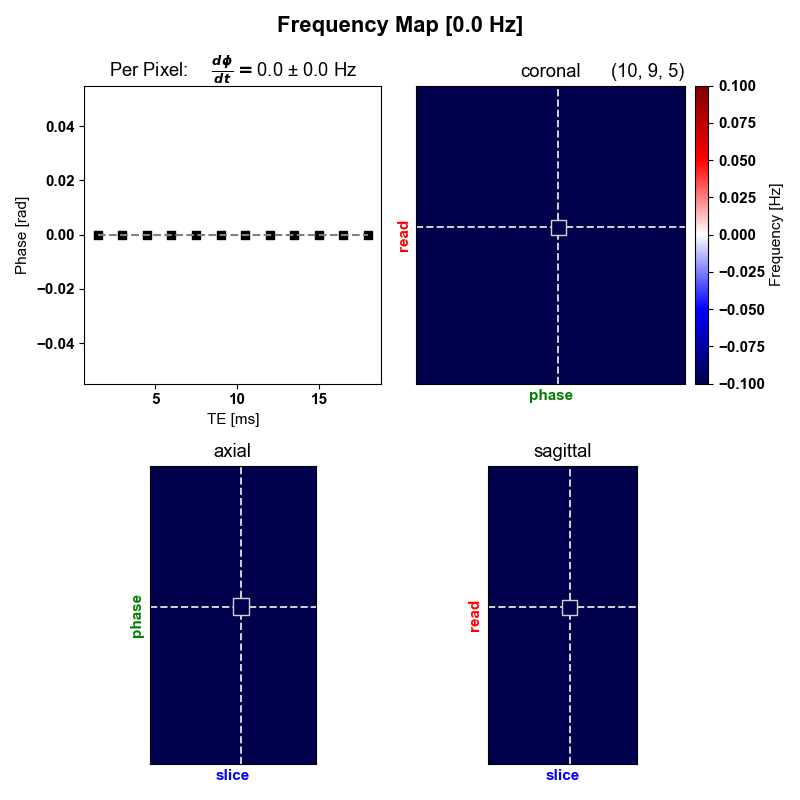

In [9]:
umge_dummy_class.plot_results(
     param_dict={
         'fmap': {'cmap': 'seismic'}
     },
     anatref=anatomical
 )

### Plot uMGE

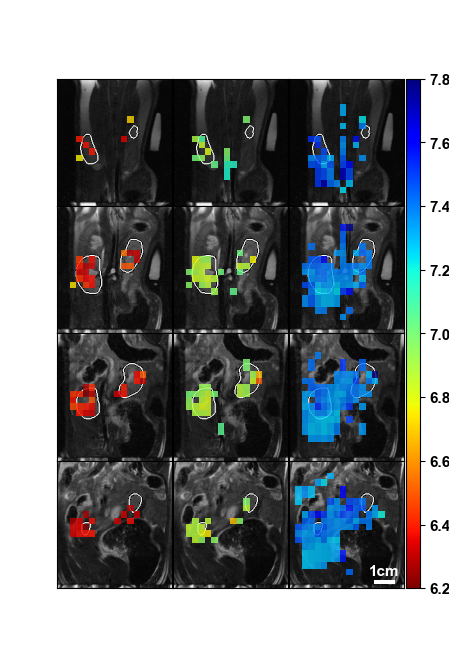

In [ ]:
vmin = 6.2
vmax=7.8
norm = plt.Normalize(vmin, vmax)


# setup figure
fig = plt.figure(figsize=(3.45980315*1.3,5.090629921*1.3))
gs = gridspec.GridSpec(4, 3, wspace=0.0, hspace=0)


#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1



#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0



# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)


for slice_idx in range(3,7):
    for idx in range(0,3):
        ax = fig.add_subplot(gs[slice_idx-3, idx])

        hyper_data = uMGE.multi_comp_pHmaps[idx,...]
        anat_image = anat_data_shifted[..., slice_idx*3+2]
        contours = get_mask_contours(shifted_mask[..., slice_idx*3+2])

        ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
        ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
        ax.imshow(hyper_data[..., slice_idx], extent=extent_hyper, origin='lower', vmin=vmin, vmax=vmax, cmap='jet_r', alpha=0.8)


        ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

        if idx == 2 and slice_idx == 6:
            scalebar = ScaleBar(**SCALEBAR_ARGS)
            ax.add_artist(scalebar)
            scalebar.frameon = False # Hide the frame around the scale bar

        
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.005, b, 0.03, h*4])

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap='jet_r'),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticklabels = np.arange(vmin, vmax+0.2, 0.2)

cbar.set_ticks(cbar_ticklabels)
cbar.set_label("[pH]", fontdict=font)

In [11]:
plt.savefig("./Images/In_Vivo_uMGE_pH_maps_export_all_kidney_slices.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

### Plot CSI

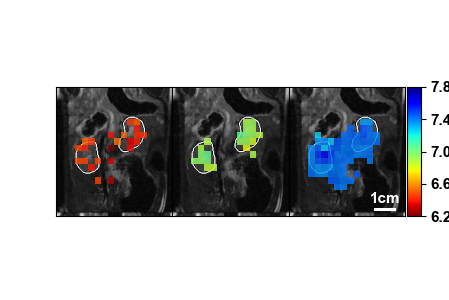

In [ ]:
vmin = 6.2
vmax=7.8
norm = plt.Normalize(vmin, vmax)


# setup figure
fig = plt.figure(figsize=(3.45980315*1.3,3.0))
hspace = 0
gs = gridspec.GridSpec(1, 3, wspace=0.0, hspace=hspace)


#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1

#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0

contours = get_mask_contours(shifted_mask[..., comparison_slice*3+2])

# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)
anat_image = anat_data_shifted[..., comparison_slice*3+2]


for idx in range(0,3):
    ax = fig.add_subplot(gs[0, idx])
    
    csi_data = compinded_pH_map[idx,:,:,5]
    
    ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
    ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
    ax.imshow(csi_data, extent=extent_hyper, origin='lower', vmin=vmin, vmax=vmax, cmap='jet_r', alpha=0.8)

    
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    
    if idx == 2:
        scalebar = ScaleBar(**SCALEBAR_ARGS)
        ax.add_artist(scalebar)
        scalebar.frameon = False # Hide the frame around the scale bar
    
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.005, b, 0.03, h])

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap='jet_r'),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticklabels = np.arange(vmin, vmax+0.4, 0.4)

cbar.set_ticks(cbar_ticklabels)

In [11]:
plt.savefig("./Images/In_Vivo_CSI_pH_maps.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

### Difference Plot

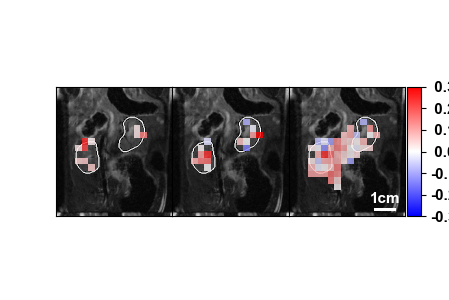

In [ ]:
vmin = -0.3
vmax=0.3
norm = plt.Normalize(vmin, vmax)

# setup figure
fig = plt.figure(figsize=(3.45980315*1.3,3.0))
hspace = 0
gs = gridspec.GridSpec(1, 3, wspace=0.0, hspace=hspace)

all_difference_maps =[]


#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1

#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0

contours = get_mask_contours(shifted_mask[..., comparison_slice*3+2])

# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)
anat_image = anat_data_shifted[..., comparison_slice*3+2]


for idx in range(0,3):
    ax = fig.add_subplot(gs[0, idx])
    
    csi_data = compinded_pH_map[idx,:,:,5]
    umge_data = uMGE.multi_comp_pHmaps[idx,:,:,comparison_slice]
    
    difference_map = csi_data - umge_data
    
    all_difference_maps = np.append(all_difference_maps, difference_map.compressed())
    
    ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
    ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
    ax.imshow(difference_map, extent=extent_hyper, origin='lower',vmin=vmin, vmax=vmax,  cmap='bwr', alpha=0.8)
       
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    
    if idx == 2:
        scalebar = ScaleBar(**SCALEBAR_ARGS)
        ax.add_artist(scalebar)
        scalebar.frameon = False # Hide the frame around the scale bar
        
    
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.005, b, 0.03, h])

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap='bwr'),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticks = np.arange(vmin, vmax+0.1, 0.1)
cbar_ticklabels = np.array(["-0.3", "-0.2","-0.1"," 0.0"," 0.1"," 0.2"," 0.3"], dtype=str)


cbar.set_ticks(cbar_ticks)
_=cbar.ax.set_yticklabels(cbar_ticklabels)

In [13]:
print("Mean of all difference values:",np.nanmean(all_difference_maps), "+-",np.nanstd(all_difference_maps))

Mean of all difference values: 0.05596258789502268 +- 0.08841046251281957


In [14]:
plt.savefig("./Images/In_Vivo_Difference_Map.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

### Meanhyper_data pH Plot uMGE

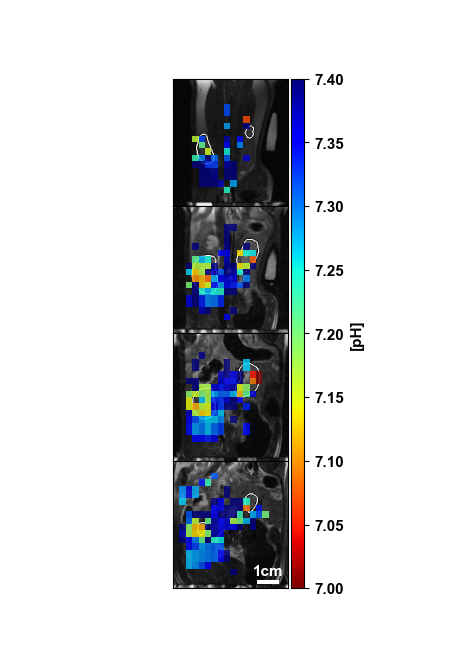

In [ ]:
vmin = 7.0
vmax=7.4
norm = plt.Normalize(vmin, vmax)


# setup figure
fig = plt.figure(figsize=(3.45980315*1.3,5.090629921*1.3))
hspace = 0
gs = gridspec.GridSpec(4, 1, wspace=0.0, hspace=hspace)

#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1

#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0

# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)

for idx in range(3,7):
    #for i in range(0,3):
    ax = fig.add_subplot(gs[idx-3,0])

    hyper_data = uMGE.multi_mean_pHmap
    anat_image = anat_data_shifted[..., idx*3+2]

    contours = get_mask_contours(shifted_mask[..., idx*3+2])
    

    ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
    ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
    ax.imshow(hyper_data[..., idx], extent=extent_hyper, origin='lower', vmin=vmin, vmax=vmax, cmap='jet_r', alpha=0.8)


    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

    if idx == 6:
        scalebar = ScaleBar(**SCALEBAR_ARGS)
        ax.add_artist(scalebar)
        scalebar.frameon = False # Hide the frame around the scale bar
    
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.007, b, 0.03, h*4])

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap='jet_r'),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticklabels = np.arange(vmin, vmax, 0.05)

cbar.set_ticks(cbar_ticklabels)
cbar.set_label("[pH]", fontdict=font)

In [18]:
plt.savefig("./Images/In_Vivo_Mean_pH.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

## Plot Mean Kidney pH CSI

In [16]:
def calculate_mean_pH_map(ampl, pH):
            
    def calc_mean(idx):

        weighted_pH = 0

        index_not_nan = np.argwhere(~np.isnan(pH[(..., *idx)]))

        for map_idx in index_not_nan:
            weighted_pH = weighted_pH + (pH[(map_idx, *idx)]*(np.abs(ampl[(map_idx, *idx)])/np.nansum(np.abs(ampl[(index_not_nan, *idx)]))))
        
        if weighted_pH == 0:
            return float("Nan")
        else:

            return np.squeeze(weighted_pH)


    _, dim_read, dim_phase = ampl.shape
    index_list = list(np.ndindex(dim_read, dim_phase))

        # serial solve for mutliple voxels in parallel
    solution_serial = Parallel(n_jobs=4)(
        delayed(calc_mean)(idx) for idx in index_list)
    

    mean_ph_map = np.array(solution_serial).reshape(
        dim_read, dim_phase, -1
    )

    mean_ph_map = np.squeeze(mean_ph_map)
        
    return mean_ph_map

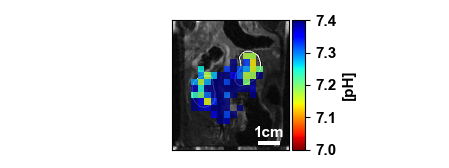

In [ ]:
vmin = 7.0
vmax=7.4
norm = plt.Normalize(vmin, vmax)


# setup figure
fig, ax = plt.subplots(figsize=(3.45980315*1.3,1.68))


#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1

#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0

contours = get_mask_contours(shifted_mask[..., comparison_slice*3+2])

# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)
anat_image = anat_data_shifted[..., comparison_slice*3+2]

#calculate mean pH map 
mean_pH_map = calculate_mean_pH_map(compinded_ampl_map[:,:,:,5], compinded_pH_map[:,:,:,5])

ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
ax.imshow(mean_pH_map, extent=extent_hyper, origin='lower', vmin=vmin, vmax=vmax, cmap='jet_r', alpha=0.8)


ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

scalebar = ScaleBar(**SCALEBAR_ARGS)
ax.add_artist(scalebar)
scalebar.frameon = False # Hide the frame around the scale bar
    
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.007, b, 0.03, h])

cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap='jet_r'),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticklabels = np.arange(vmin, vmax+0.1, 0.1)

cbar.set_ticks(cbar_ticklabels)
cbar.set_label("[pH]", fontdict=font)

In [18]:
plt.savefig("./Images/In_Vivo_Mean_pH_CSI.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

## Difference of Mean

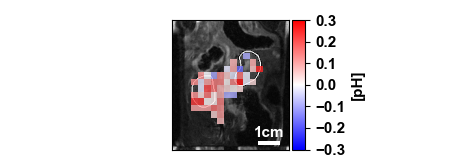

In [ ]:
cmap = "bwr"

vmin = -0.3
vmax=0.3
norm = plt.Normalize(vmin, vmax)

# setup figure
fig, ax = plt.subplots(figsize=(3.45980315*1.3,1.68))




#load mask, anatomical slice and overlay slice number
comparison_slice = int(META['Overlay_Slice'])-1
kidneys_mask_both = MV(np.load("./ROIs/Kidneys_Both.npy"))
kidneys_mask_both[kidneys_mask_both > 0] = 1

#shift mask and digitize mask values again
shifted_mask = apply_shift(anat_image = kidneys_mask_both, mat_hyper=uMGE.multi_comp_pHmaps.shape[1:], mat_anat=kidneys_mask_both.shape, fov_hyper=uMGE.fov, fov_anat=anatomical.fov)
shifted_mask[shifted_mask > 0.9] = 1
shifted_mask[shifted_mask < 0.9] = 0

contours = get_mask_contours(shifted_mask[..., comparison_slice*3+2])

# load and shift anatomical data
anat_data_shifted = apply_shift(anat_image = anatomical.data,mat_hyper=uMGE.multi_comp_pHmaps.shape[1:],mat_anat=anatomical.data.shape,fov_hyper=uMGE.fov,fov_anat=anatomical.fov)
anat_image = anat_data_shifted[..., comparison_slice*3+2]

mean_pH_map_MEpHISDO = uMGE.multi_mean_pHmap

#calculate mean pH map 
mean_pH_map_CSI = calculate_mean_pH_map(compinded_ampl_map[:,:,:,5], compinded_pH_map[:,:,:,5])

csi_data = mean_pH_map_CSI
umge_data = mean_pH_map_MEpHISDO[:,:,comparison_slice]
difference_map = csi_data - umge_data

ax.imshow(anat_image, extent=extent_anat, origin='lower', cmap='gray')
ax.imshow(contours, extent=extent_anat, origin='lower', cmap= "maks_contour_cmap",alpha=1)
ax.imshow(difference_map, extent=extent_hyper, origin='lower',vmin=vmin, vmax=vmax,  cmap=cmap, alpha=0.8)


ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

scalebar = ScaleBar(**SCALEBAR_ARGS)
ax.add_artist(scalebar)
scalebar.frameon = False # Hide the frame around the scale bar
    
l, b, w, h = ax.get_position().bounds  # get position of third anatomical
cax = fig.add_axes([l +w+ 0.007, b, 0.03, h])


cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cax,
    orientation="vertical",
)

#set colorbar ticks
cbar_ticks = np.arange(vmin, vmax+0.1, 0.1)



#set colorbar ticks
cbar_ticklabels = np.arange(vmin, vmax+0.1, 0.1)

cbar.set_ticks(cbar_ticklabels)
cbar.set_label("[pH]", fontdict=font)

In [20]:
print("Mean of all difference values:",np.nanmean(difference_map), "+-",np.nanstd(difference_map))

Mean of all difference values: 0.06979876225927208 +- 0.093317884258968


In [21]:
plt.savefig("./Images/In_Vivo_Mean_Differences.svg", dpi=600, bbox_inches="tight", pad_inches=0.00, transparent=True)

## Plot Spectra Pre Saturation

In [ ]:
# get all spectra
all_spectra = []


for scan_i in range(1,9):
    
    uMGE= umpireMGE.load(f"./export/MEpHISDO_object_scan_{scan_i}.pickle")    
    
    spectra, f_axis = uMGE.spectral_data
    
    all_spectra.append( spectra)
  

all_spectra = np.array(all_spectra)

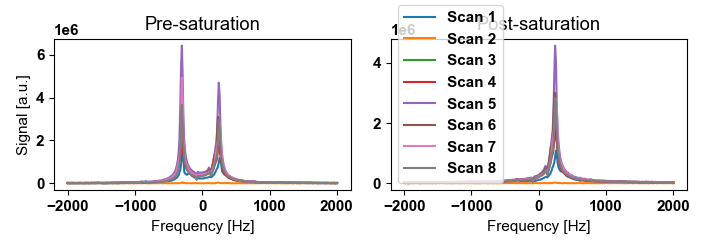

In [27]:


fig, ax = plt.subplots(1,2,figsize=[7.08661,2.5])


for scan_i in range(0,8):
    ax[0].plot(f_axis[860:1189], np.abs(all_spectra[scan_i,0,860:1189]))
    ax[0].set_title("Pre-saturation")
    ax[0].set_xlabel("Frequency [Hz]")
    ax[0].set_ylabel("Signal [a.u.]")
    #ax[0].set_yticks([])

    ax[1].plot(f_axis[860:1189], np.abs(all_spectra[scan_i,2,860:1189]), label = "Scan " + str(scan_i+1))
    ax[1].set_title("Post-saturation")
    ax[1].set_xlabel("Frequency [Hz]")
    #ax[1].set_yticks([])
    

ax[1].legend()
fig.tight_layout()



In [94]:
plt.savefig("./Images/Saturation Spectra.svg", dpi=600,transparent=True)